# Introduction à Pandas

**Pandas** est une bibliothèque Python utilisée pour manipuler, nettoyer et analyser des données structurées.

Elle repose principalement sur deux structures :

- **`Series`** : structure à une dimension, comparable à une colonne de données ;
- **`DataFrame`** : structure à deux dimensions, comparable à un tableau comportant des lignes et des colonnes.

## Objectifs d’apprentissage

À la fin de ce notebook, vous devriez être capables de :

1. créer et manipuler une `Series` ;
2. accéder aux données avec les index, `loc` et `iloc` ;
3. effectuer des calculs et des filtrages ;
4. gérer les valeurs manquantes ;
5. créer et explorer un `DataFrame` ;
6. sélectionner des lignes et des colonnes ;
7. fusionner plusieurs DataFrames ;
8. importer des données depuis différents formats ;
9. travailler avec des index multiples ;
10. manipuler des dates et des catégories.

> **Conseil :** exécutez les cellules dans l’ordre. Plusieurs exemples réutilisent des variables créées précédemment.

In [ ]:
!pip install -r ../requirements.txt
import pandas as pd
import numpy as np

# 1. Les `Series`

Une **Series** est une structure de données unidimensionnelle.

Elle contient :

- des **valeurs** ;
- un **index** associé à chaque valeur.

On peut la voir comme une colonne de tableau avec des étiquettes.

## 1.1 Créer une `Series`

In [3]:
s = pd.Series([1, 2, 3], index=["a", "b", "c"])
s

a    1
b    2
c    3
dtype: int64

On peut également créer une `Series` à partir d'une simple liste.  
Si aucun index n'est fourni, Pandas crée automatiquement un index numérique commençant à `0`.

In [4]:
data = [10, 20, 30, 40, 50]
series = pd.Series(data)
series

0    10
1    20
2    30
3    40
4    50
dtype: int64

### Ajouter un index personnalisé

In [5]:
indexes = ['a', 'b', 'c', 'd', 'e']
series_with_indexes = pd.Series(data, index=indexes)
series_with_indexes

a    10
b    20
c    30
d    40
e    50
dtype: int64

### Créer une `Series` à partir d’un dictionnaire

In [6]:
data_dict = {'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5}
series_with_dict = pd.Series(data_dict)
series_with_dict

a    1
b    2
c    3
d    4
e    5
dtype: int64

> **À retenir**
>
> - avec une liste, Pandas génère un index numérique par défaut ;
> - avec un index fourni, on contrôle les étiquettes ;
> - avec un dictionnaire, les clés deviennent naturellement les index.

## 1.2 Accéder aux éléments d’une `Series`

On peut accéder aux valeurs de plusieurs façons. Pour éviter les ambiguïtés, on privilégie :

- `loc[]` pour accéder **par étiquette** ;
- `iloc[]` pour accéder **par position**.

In [7]:
# Accès par position
series.iloc[2]

np.int64(30)

In [8]:
# Accès par étiquette
series_with_dict.loc['c']

np.int64(3)

In [9]:
# Slicing par position : positions 1 à 2
series.iloc[1:3]

1    20
2    30
dtype: int64

In [10]:
# Plusieurs valeurs consécutives
series.iloc[1:4]

1    20
2    30
3    40
dtype: int64

> `iloc[1:4]` inclut les positions `1`, `2` et `3`, mais exclut la position `4`, comme un slice Python classique.

## 1.3 Calculs et méthodes descriptives

In [11]:
print("Somme :", series.sum())
print("Moyenne :", series.mean())
print("Maximum :", series.max())

Somme : 150
Moyenne : 30.0
Maximum : 50


### Examiner rapidement le contenu

In [12]:
series.head(3)

0    10
1    20
2    30
dtype: int64

In [13]:
series.tail(2)

3    40
4    50
dtype: int64

In [14]:
series.shape

(5,)

In [15]:
series.describe()

count     5.000000
mean     30.000000
std      15.811388
min      10.000000
25%      20.000000
50%      30.000000
75%      40.000000
max      50.000000
dtype: float64

In [16]:
series.info()

<class 'pandas.Series'>
RangeIndex: 5 entries, 0 to 4
Series name: None
Non-Null Count  Dtype
--------------  -----
5 non-null      int64
dtypes: int64(1)
memory usage: 172.0 bytes


`describe()` fournit un résumé statistique, tandis que `info()` donne surtout des informations sur le type des données, le nombre de valeurs et la mémoire utilisée.

## 1.4 Modifier et analyser les valeurs

In [17]:
series_mod = series.copy()
series_mod.iloc[0] = 30
series_mod

0    30
1    20
2    30
3    40
4    50
dtype: int64

In [18]:
series_mod.unique()

array([30, 20, 40, 50])

In [19]:
series_mod.nunique()

4

- `unique()` retourne les différentes valeurs présentes ;
- `nunique()` retourne leur nombre.

## 1.5 Opérations entre `Series`

In [20]:
result_series = series_with_dict * series_with_indexes
result_series

a     10
b     40
c     90
d    160
e    250
dtype: int64

Pandas aligne les valeurs **selon les index** avant d’effectuer l’opération.

C’est une différence importante par rapport à une simple liste Python.

## 1.6 Transformer les valeurs avec `apply()` et `map()`

In [21]:
series.apply(lambda value: value * 2)

0     20
1     40
2     60
3     80
4    100
dtype: int64

In [22]:
s = series_with_dict.copy()
s.map({1: 'one', 2: 'two', 3: 'three'})

a      one
b      two
c    three
d      NaN
e      NaN
dtype: str

`map()` remplace ici certaines valeurs selon un dictionnaire.  
Les valeurs qui ne possèdent pas de correspondance deviennent `NaN`.

## 1.7 Trier une `Series`

In [23]:
series_triee = series.copy()
series_triee.sort_values()

0    10
1    20
2    30
3    40
4    50
dtype: int64

In [24]:
series_with_dict.sort_index()

a    1
b    2
c    3
d    4
e    5
dtype: int64

- `sort_values()` trie selon les **valeurs** ;
- `sort_index()` trie selon les **index**.

## 1.8 Gérer les valeurs manquantes

In [25]:
series_na = series.copy()
series_na.iloc[2] = pd.NA
series_na

0    10.0
1    20.0
2     NaN
3    40.0
4    50.0
dtype: float64

In [26]:
series_na.isnull().value_counts()

False    4
True     1
Name: count, dtype: int64

In [27]:
series_na.fillna(0)

0    10.0
1    20.0
2     0.0
3    40.0
4    50.0
dtype: float64

Les valeurs manquantes sont fréquentes dans les jeux de données réels.

Quelques méthodes utiles :

- `isnull()` / `isna()` : détecter les valeurs absentes ;
- `fillna()` : remplacer les valeurs manquantes ;
- `dropna()` : supprimer les observations manquantes.

# 2. Filtrer une `Series`

Le **filtrage booléen** permet de conserver seulement les valeurs qui respectent une condition.

In [28]:
series[series > 30]

3    40
4    50
dtype: int64

In [29]:
series[series == 20]

1    20
dtype: int64

In [30]:
series[series != 20]

0    10
2    30
3    40
4    50
dtype: int64

### Combiner plusieurs conditions

In [31]:
series[(series > 20) & (series < 50)]

2    30
3    40
dtype: int64

Avec Pandas :

- `&` signifie **ET** ;
- `|` signifie **OU** ;
- chaque condition doit généralement être placée entre parenthèses.

In [32]:
series[series.isin([20, 40])]

1    20
3    40
dtype: int64

### Filtrer du texte

In [33]:
str_series = pd.Series(['pomme', 'banane', 'tomate', 'cerises', 'patate'])
str_series[str_series.str.startswith('p')]

0     pomme
4    patate
dtype: str

## 2.1 La méthode `where()`

`where()` conserve les valeurs qui respectent une condition.

Les autres valeurs sont remplacées par `NaN`, ou par une valeur de remplacement si celle-ci est fournie.

In [34]:
s[s % 2 == 0]

b    2
d    4
dtype: int64

In [35]:
s.where(s % 2 == 0)

a    NaN
b    2.0
c    NaN
d    4.0
e    NaN
dtype: float64

In [36]:
s.where(s % 2 == 0, 'Odd num')

a    Odd num
b          2
c    Odd num
d          4
e    Odd num
dtype: object

In [37]:
s.where(s % 2 == 0, s**2)

a     1
b     2
c     9
d     4
e    25
dtype: int64

In [38]:
s.where(s % 2 == 0).dropna()

b    2.0
d    4.0
dtype: float64

In [39]:
s.where(s % 2 == 0).fillna(0)

a    0.0
b    2.0
c    0.0
d    4.0
e    0.0
dtype: float64

> **Différence importante**
>
> `s[s % 2 == 0]` retire les éléments qui ne respectent pas la condition, tandis que `where()` conserve la structure de la `Series` et remplace les autres valeurs.

# 3. Les `DataFrame`

Un **DataFrame** est une structure tabulaire à deux dimensions.

Il possède :

- des lignes ;
- des colonnes ;
- un index ;
- éventuellement des types différents d’une colonne à l’autre.

## 3.1 Créer un `DataFrame` à partir d’un dictionnaire

In [40]:
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35]
}

df = pd.DataFrame(data)
df

,Name,Age
0,Alice,25
1,Bob,30
2,Charlie,35


## 3.2 Exemple : pays, population et superficie

In [41]:
countries = ['France', 'Canada', 'Brésil', 'Australie', 'Inde',
             'Chine', 'États-Unis', 'Russie', 'Mexique', 'Japon']

population = [67.39, 37.59, 211.05, 25.36, 1380,
              1441, 331, 146, 128.93, 126.3]

area = [551695, 9984670, 8515767, 7692024, 3287263,
        9596961, 9833517, 17098242, 1964375, 377975]

sc = pd.DataFrame({
    'Country': countries,
    'Pop': population,
    'Area': area
})

sc

,Country,Pop,Area
0,France,67.39,551695
1,Canada,37.59,9984670
2,Brésil,211.05,8515767
3,Australie,25.36,7692024
4,Inde,1380.00,3287263
5,Chine,1441.00,9596961
6,États-Unis,331.00,9833517
7,Russie,146.00,17098242
8,Mexique,128.93,1964375
9,Japon,126.30,377975


## 3.3 Créer un `DataFrame` à partir d’une liste de listes

In [42]:
columns = ['Name', 'Age', 'Salary']

data_list = [
    ['Alice', 25, 50000],
    ['Bob', 30, 60000],
    ['Charlie', 22, 45000]
]

df_list = pd.DataFrame(data_list, columns=columns)
df_list

,Name,Age,Salary
0,Alice,25,50000
1,Bob,30,60000
2,Charlie,22,45000


In [43]:
df_list.dtypes

Name        str
Age       int64
Salary    int64
dtype: object

## 3.4 Filtrer les lignes d’un `DataFrame`

In [44]:
df_list[df_list['Age'] > 25]

,Name,Age,Salary
1,Bob,30,60000


Ici, la condition `df_list['Age'] > 25` produit une série de valeurs booléennes.  
Le DataFrame conserve uniquement les lignes pour lesquelles la condition vaut `True`.

## 3.5 Explorer rapidement un `DataFrame`

In [45]:
sc.head()

,Country,Pop,Area
0,France,67.39,551695
1,Canada,37.59,9984670
2,Brésil,211.05,8515767
3,Australie,25.36,7692024
4,Inde,1380.00,3287263


In [46]:
sc.tail(3)

,Country,Pop,Area
7,Russie,146.00,17098242
8,Mexique,128.93,1964375
9,Japon,126.30,377975


In [47]:
sc.describe()

,Pop,Area
count,10.000000,1.000000e+01
mean,389.462000,6.890249e+06
std,545.554335,5.300792e+06
min,25.360000,3.779750e+05
25%,82.117500,2.295097e+06
50%,137.465000,8.103896e+06
75%,301.012500,9.774378e+06
max,1441.000000,1.709824e+07


In [48]:
sc.dtypes

Country        str
Pop        float64
Area         int64
dtype: object

In [49]:
sc.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  10 non-null     str    
 1   Pop      10 non-null     float64
 2   Area     10 non-null     int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 372.0 bytes


### Sélectionner une colonne

In [50]:
sc['Pop']

0      67.39
1      37.59
2     211.05
3      25.36
4    1380.00
5    1441.00
6     331.00
7     146.00
8     128.93
9     126.30
Name: Pop, dtype: float64

In [51]:
sc.Area

0      551695
1     9984670
2     8515767
3     7692024
4     3287263
5     9596961
6     9833517
7    17098242
8     1964375
9      377975
Name: Area, dtype: int64

La notation `df['colonne']` est généralement préférable à `df.colonne`, car elle fonctionne même lorsque le nom de colonne contient des espaces ou entre en conflit avec une méthode Pandas.

# 4. Fusionner des DataFrames avec `merge()`

In [52]:
df1 = pd.DataFrame({
    'Employee': ['Alice', 'Bob'],
    'Department': ['HR', 'Finance']
})

df2 = pd.DataFrame({
    'Employee': ['Alice', 'Bob'],
    'Hire_Date': [2015, 2018]
})

In [53]:
df1

,Employee,Department
0,Alice,HR
1,Bob,Finance


In [54]:
df2

,Employee,Hire_Date
0,Alice,2015
1,Bob,2018


In [55]:
pd.merge(df1, df2, on='Employee')

,Employee,Department,Hire_Date
0,Alice,HR,2015
1,Bob,Finance,2018


`merge()` permet de combiner des tables qui possèdent une clé commune.

Ici, la colonne `Employee` sert de clé de correspondance.

# 5. Importer des données

Pandas peut charger plusieurs formats de fichiers.

Les exemples suivants supposent que les fichiers sont disponibles dans le dossier indiqué par `path`.

> **À adapter selon votre environnement :**
>
> - Google Colab : `/content/sample_data/`
> - Jupyter local : utilisez le chemin réel vers votre dossier de données.

In [56]:
path = '../data/raw/'

In [57]:
# Fichier CSV
df_titanic = pd.read_csv(path + 'titanic.csv')
df_titanic.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [58]:
# Fichier Excel
df_excel = pd.read_excel(path + 'Data.xlsx')
df_excel.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [82]:
# Fichier JSON
df_json = pd.read_json(path + 'world-population-2020.json')
df_json.head()

,position,country,population,yearly_change,net_change,density_per_square_km,land_are_in_square_km,migrants_net,fertility_rate,median_age,urban_population,world_share
0,1,China,"1,439,323,776",0.39 %,"5,540,090",153,"9,388,211","-348,399",1.7,38,61 %,18.47 %
1,2,India,"1,380,004,385",0.99 %,"13,586,631",464,"2,973,190","-532,687",2.2,28,35 %,17.70 %
2,3,United States,"331,002,651",0.59 %,"1,937,734",36,"9,147,420","954,806",1.8,38,83 %,4.25 %
3,4,Indonesia,"273,523,615",1.07 %,"2,898,047",151,"1,811,570","-98,955",2.3,30,56 %,3.51 %
4,5,Pakistan,"220,892,340",2.00 %,"4,327,022",287,"770,880","-233,379",3.6,23,35 %,2.83 %


Matplotlib is building the font cache; this may take a moment.


<Axes: >

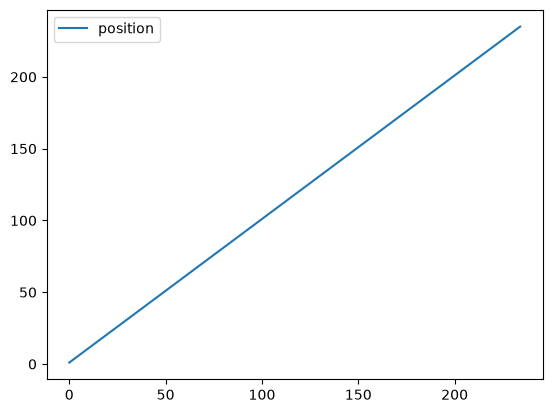

In [83]:
df_json.plot()

<Axes: >

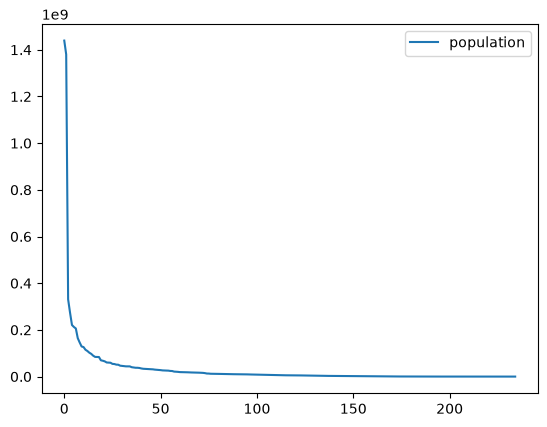

In [97]:
df_json['population'].str.replace(',', '').astype(int).plot(legend=True )

## 5.1 Inspecter les données importées

In [60]:
df_titanic.shape

(887, 8)

In [61]:
df_titanic.describe()

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [62]:
df_excel.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [63]:
df_titanic.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard',
       'Parents/Children Aboard', 'Fare'],
      dtype='str')

### Exemple de corrélation entre deux colonnes

In [64]:
df_titanic[['Age', 'Survived']].corr()

,Age,Survived
Age,1.000000,-0.059665
Survived,-0.059665,1.000000


La méthode `corr()` calcule ici le coefficient de corrélation entre les colonnes numériques sélectionnées.

Une corrélation ne démontre pas à elle seule une relation de cause à effet.

# 6. Les index multiples (`MultiIndex`)

In [65]:
df_house = pd.read_csv(path + 'HousePrices.csv')
df_house.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [66]:
df_house_multi = df_house.set_index(['city', 'date'])
df_house_multi.head()

,,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,statezip,country
city,date,,,,,,,,,,,,,,,,
Shoreline,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,WA 98133,USA
Seattle,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,WA 98119,USA
Kent,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,WA 98042,USA
Bellevue,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,WA 98008,USA
Redmond,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,WA 98052,USA


In [67]:
df_house_multi.index

MultiIndex([(   'Shoreline', '2014-05-02 00:00:00'),
            (     'Seattle', '2014-05-02 00:00:00'),
            (        'Kent', '2014-05-02 00:00:00'),
            (    'Bellevue', '2014-05-02 00:00:00'),
            (     'Redmond', '2014-05-02 00:00:00'),
            (     'Seattle', '2014-05-02 00:00:00'),
            (     'Redmond', '2014-05-02 00:00:00'),
            ('Maple Valley', '2014-05-02 00:00:00'),
            (  'North Bend', '2014-05-02 00:00:00'),
            (     'Seattle', '2014-05-02 00:00:00'),
            ...
            (      'Renton', '2014-07-08 00:00:00'),
            (     'Seattle', '2014-07-08 00:00:00'),
            ( 'Federal Way', '2014-07-08 00:00:00'),
            (      'Auburn', '2014-07-08 00:00:00'),
            (        'Kent', '2014-07-09 00:00:00'),
            (     'Seattle', '2014-07-09 00:00:00'),
            (    'Bellevue', '2014-07-09 00:00:00'),
            (      'Renton', '2014-07-09 00:00:00'),
            (     'Seattle', '

### Sélectionner un premier niveau d’index

In [68]:
df_house_multi.loc['Seattle']

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,statezip,country
date,,,,,,,,,,,,,,,,
2014-05-02 00:00:00,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,WA 98119,USA
2014-05-02 00:00:00,4.900000e+05,2.0,1.00,880,6380,1.0,0,0,3,880,0,1938,1994,522 NE 88th St,WA 98115,USA
2014-05-02 00:00:00,6.400000e+05,4.0,2.00,1520,6200,1.5,0,0,3,1520,0,1945,2010,6811 55th Ave NE,WA 98115,USA
2014-05-02 00:00:00,1.400000e+06,4.0,2.50,2920,4000,1.5,0,0,5,1910,1010,1909,1988,3838-4098 44th Ave NE,WA 98105,USA
2014-05-02 00:00:00,3.650000e+05,3.0,1.00,1090,6435,1.0,0,0,4,1090,0,1955,2009,2504 SW Portland Ct,WA 98106,USA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-07-07 00:00:00,4.060625e+05,2.0,1.00,1290,4650,1.0,0,0,4,1290,0,1906,1990,312 NE 81st St,WA 98115,USA
2014-07-07 00:00:00,4.868950e+05,3.0,1.00,1890,3330,1.5,0,0,4,1390,500,1901,0,4324 Dayton Ave N,WA 98103,USA
2014-07-08 00:00:00,3.961667e+05,3.0,1.75,1880,5752,1.0,0,0,4,940,940,1945,0,3529 SW Webster St,WA 98126,USA


### Sélectionner une ville puis une date

In [69]:
df_house_multi.loc['Seattle'].loc['2014-05-02 00:00:00']

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,statezip,country
date,,,,,,,,,,,,,,,,
2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,WA 98119,USA
2014-05-02 00:00:00,490000.0,2.0,1.00,880,6380,1.0,0,0,3,880,0,1938,1994,522 NE 88th St,WA 98115,USA
2014-05-02 00:00:00,640000.0,4.0,2.00,1520,6200,1.5,0,0,3,1520,0,1945,2010,6811 55th Ave NE,WA 98115,USA
2014-05-02 00:00:00,1400000.0,4.0,2.50,2920,4000,1.5,0,0,5,1910,1010,1909,1988,3838-4098 44th Ave NE,WA 98105,USA
2014-05-02 00:00:00,365000.0,3.0,1.00,1090,6435,1.0,0,0,4,1090,0,1955,2009,2504 SW Portland Ct,WA 98106,USA
2014-05-02 00:00:00,1200000.0,5.0,2.75,2910,9480,1.5,0,0,3,2910,0,1939,1969,3534 46th Ave NE,WA 98105,USA
2014-05-02 00:00:00,750000.0,3.0,1.75,2240,10578,2.0,0,0,5,1550,690,1923,0,3225 NE 92nd St,WA 98115,USA
2014-05-02 00:00:00,626000.0,3.0,2.25,1750,1572,2.5,0,0,3,1470,280,2005,0,3140 Franklin Ave E,WA 98102,USA
2014-05-02 00:00:00,495000.0,4.0,1.75,1600,6380,1.0,0,0,3,1130,470,1959,1989,2021 NE 100th St,WA 98125,USA


Un `MultiIndex` est utile lorsqu’une ligne est naturellement identifiée par plusieurs clés, par exemple :

- une ville ;
- une date.

# 7. Parcourir les lignes d’un DataFrame

La méthode `iterrows()` permet de parcourir les lignes une à une.

Elle est pratique pour apprendre ou pour certains traitements particuliers, mais on privilégie généralement les opérations vectorisées de Pandas lorsqu’elles sont possibles.

In [70]:
for index, row in df_titanic.head().iterrows():
    print("Index :", index,
          "| Age :", row['Age'],
          "| Survived :", row['Survived'])

Index : 0 | Age : 22.0 | Survived : 0
Index : 1 | Age : 38.0 | Survived : 1
Index : 2 | Age : 26.0 | Survived : 1
Index : 3 | Age : 35.0 | Survived : 1
Index : 4 | Age : 35.0 | Survived : 0


# 8. Manipuler des dates avec Pandas

## 8.1 Créer une plage de dates

In [71]:
date_range = pd.date_range(
    start='2023-01-01',
    end='2024-12-31',
    freq='D'
)

date_range

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', length=731, freq='D')

## 8.2 Convertir du texte en date

In [72]:
data = {
    'Date': ['2025-01-01', '2025-02-18', '2025-03-20']
}

df_dates = pd.DataFrame(data)
df_dates['Date'] = pd.to_datetime(df_dates['Date'])

df_dates

,Date
0,2025-01-01
1,2025-02-18
2,2025-03-20


In [73]:
df_dates.dtypes

Date    datetime64[us]
dtype: object

In [74]:
date_range.dtype

dtype('<M8[us]')

## 8.3 Extraire des composantes d’une date

In [75]:
df_dates['Day'] = df_dates['Date'].dt.day
df_dates

,Date,Day
0,2025-01-01,1
1,2025-02-18,18
2,2025-03-20,20


In [76]:
df_dates['Month'] = df_dates['Date'].dt.month
df_dates['Year'] = df_dates['Date'].dt.year

df_dates

,Date,Day,Month,Year
0,2025-01-01,1,1,2025
1,2025-02-18,18,2,2025
2,2025-03-20,20,3,2025


## 8.4 Identifier le jour de la semaine

In [77]:
df_calendar = pd.DataFrame({'Date': date_range})
df_calendar['Weekday'] = df_calendar['Date'].dt.weekday

df_calendar.head()

C:\Users\boumsar0\AppData\Local\Temp\ipykernel_37960\4149532867.py:2: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_calendar['Weekday'] = df_calendar['Date'].dt.weekday


,Date,Weekday
0,2023-01-01,6
1,2023-01-02,0
2,2023-01-03,1
3,2023-01-04,2
4,2023-01-05,3


`weekday` retourne un entier :

- lundi = `0`
- mardi = `1`
- ...
- dimanche = `6`

## 8.5 Faire des calculs sur les dates

In [78]:
df_dates['PreviousDate'] = df_dates['Date'] - pd.Timedelta(days=1)
df_dates

,Date,Day,Month,Year,PreviousDate
0,2025-01-01,1,1,2025,2024-12-31
1,2025-02-18,18,2,2025,2025-02-17
2,2025-03-20,20,3,2025,2025-03-19


In [79]:
df_dates['NextDate'] = df_dates['Date'] + pd.Timedelta(days=1)
df_dates

,Date,Day,Month,Year,PreviousDate,NextDate
0,2025-01-01,1,1,2025,2024-12-31,2025-01-02
1,2025-02-18,18,2,2025,2025-02-17,2025-02-19
2,2025-03-20,20,3,2025,2025-03-19,2025-03-21


In [80]:
df_dates['FutureDate'] = (
    df_dates['Date']
    + pd.Timedelta(weeks=2, days=3, hours=12)
)

df_dates

,Date,Day,Month,Year,PreviousDate,NextDate,FutureDate
0,2025-01-01,1,1,2025,2024-12-31,2025-01-02,2025-01-18 12:00:00
1,2025-02-18,18,2,2025,2025-02-17,2025-02-19,2025-03-07 12:00:00
2,2025-03-20,20,3,2025,2025-03-19,2025-03-21,2025-04-06 12:00:00


# 9. Données catégorielles

Une variable catégorielle contient un ensemble limité de catégories possibles.

Lorsque les catégories possèdent un ordre logique, on peut préciser cet ordre à Pandas.

In [81]:
categories = ['low', 'medium', 'high']

values = [
    'high',
    'low',
    'medium',
    'high',
    'medium',
    'low'
]

cat_vars = pd.Categorical(
    values,
    categories=categories,
    ordered=True
)

cat_vars

['high', 'low', 'medium', 'high', 'medium', 'low']
Categories (3, str): ['low' < 'medium' < 'high']

# 10. Synthèse

Dans ce notebook, nous avons manipulé les principaux outils de base de Pandas.

| Besoin | Outil principal |
|---|---|
| Créer une série | `pd.Series()` |
| Créer un tableau | `pd.DataFrame()` |
| Accéder par étiquette | `.loc[]` |
| Accéder par position | `.iloc[]` |
| Résumer des données | `.describe()` |
| Filtrer | `df[condition]` |
| Vérifier les valeurs manquantes | `.isna()` / `.isnull()` |
| Remplacer les valeurs manquantes | `.fillna()` |
| Trier | `.sort_values()` / `.sort_index()` |
| Fusionner | `pd.merge()` |
| Lire un CSV | `pd.read_csv()` |
| Lire un Excel | `pd.read_excel()` |
| Lire un JSON | `pd.read_json()` |
| Convertir une date | `pd.to_datetime()` |
| Calculer un décalage de date | `pd.Timedelta()` |
| Créer des catégories | `pd.Categorical()` |

## Bonnes pratiques

- privilégier `loc` et `iloc` pour rendre les sélections explicites ;
- examiner les données avec `head()`, `shape`, `dtypes` et `info()` ;
- vérifier les valeurs manquantes avant une analyse ;
- privilégier les opérations vectorisées plutôt que les boucles ;
- utiliser des noms de variables descriptifs.

# 11. Exercices d’application

## Exercice 1 : `Series`

Créer une `Series` représentant les ventes suivantes :

`[120, 150, 130, 170, 160, 180, 140]`

Utiliser les jours de la semaine comme index.

Puis :

1. afficher les ventes du mercredi ;
2. calculer le total des ventes ;
3. calculer la moyenne ;
4. trouver la valeur maximale ;
5. afficher uniquement les ventes supérieures à la moyenne.



## Exercice 2 : `DataFrame`

Créer un DataFrame contenant les colonnes :

- `Produit`
- `Prix`
- `Stock`

Puis :

1. afficher les trois premières lignes ;
2. afficher uniquement la colonne `Prix` ;
3. filtrer les produits dont le prix dépasse une valeur de votre choix ;
4. calculer la moyenne des prix ;
5. trier les produits par prix croissant.



## Exercice 3 : Dates

Créer un DataFrame contenant au moins cinq dates sous forme de chaînes de caractères.

Puis :

1. convertir la colonne en type `datetime` ;
2. extraire le jour, le mois et l’année ;
3. ajouter une colonne correspondant à la date située sept jours plus tard.